### Загрузка данных

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statistics import NormalDist

df = pd.read_csv("data/shopease_raw_orders.csv")

### Описательная статистика CustomerAge

In [11]:
age_raw = pd.to_numeric(df["CustomerAge"], errors="coerce")
age_values = age_raw[age_raw.between(0, 100)]

q1, median, q3 = age_values.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
age_summary = pd.DataFrame({
    "Показатель": ["Всего непустых", "Вне диапазона 0–100", "В анализе", "Среднее", "Медиана", "Стандартное отклонение", "Минимум", "Q1", "Q3", "Максимум", "За границами 1.5 IQR"],
    "Значение": [age_raw.notna().sum(), (age_raw.notna() & ~age_raw.between(0, 100)).sum(), len(age_values), age_values.mean(), median, age_values.std(), age_values.min(), q1, q3, age_values.max(), ((age_values < q1 - 1.5 * iqr) | (age_values > q3 + 1.5 * iqr)).sum()]
})
display(age_summary)

,Показатель,Значение
0,Всего непустых,9900.000000
1,Вне диапазона 0–100,15.000000
2,В анализе,9885.000000
3,Среднее,44.298331
4,Медиана,44.000000
5,Стандартное отклонение,15.314507
6,Минимум,5.000000
7,Q1,31.000000
8,Q3,58.000000
9,Максимум,70.000000


### Гистограмма и BoxPlot для CustomerAge

/tmp/ipykernel_102956/2742492310.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(age_values, vert=False)


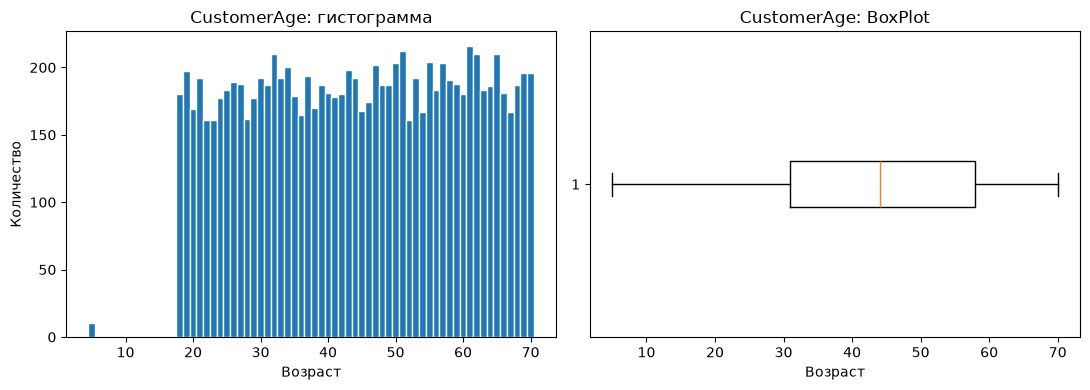

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(age_values, bins=np.arange(age_values.min() - 0.5, age_values.max() + 1.5, 1), edgecolor="white")
axes[0].set(title="CustomerAge: гистограмма", xlabel="Возраст", ylabel="Количество")
axes[1].boxplot(age_values, vert=False)
axes[1].set(title="CustomerAge: BoxPlot", xlabel="Возраст")
plt.tight_layout()
plt.show()

### Q–Q диаграмма CustomerAge

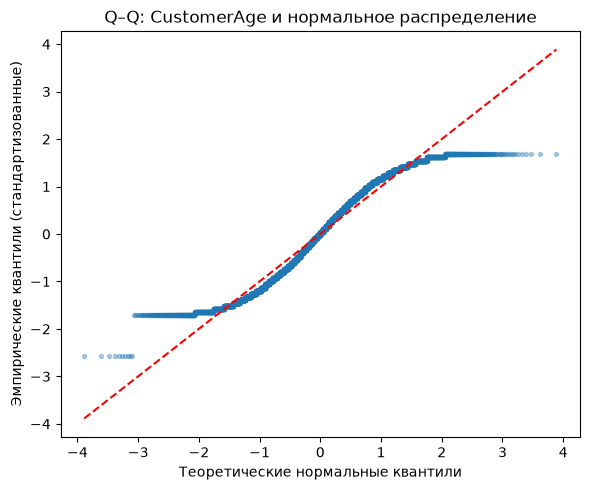

In [12]:
def normal_qq(ax, values, title):
    values = np.asarray(values)
    n = len(values)
    probabilities = (np.arange(1, n + 1) - 0.5) / n
    theoretical = np.array([NormalDist().inv_cdf(float(p)) for p in probabilities])
    empirical = np.sort((values - values.mean()) / values.std(ddof=1))
    ax.scatter(theoretical, empirical, s=8, alpha=0.35)
    limits = [min(theoretical.min(), empirical.min()), max(theoretical.max(), empirical.max())]
    ax.plot(limits, limits, "r--")
    ax.set(title=title, xlabel="Теоретические нормальные квантили", ylabel="Эмпирические квантили (стандартизованные)")

fig, ax = plt.subplots(figsize=(6, 5))
normal_qq(ax, age_values, "Q–Q: CustomerAge и нормальное распределение")
plt.tight_layout()
plt.show()

### Описательная статистика TotalAmount

In [13]:
amount_values = pd.to_numeric(df["TotalAmount"], errors="coerce").dropna()
q1, median, q3 = amount_values.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
amount_summary = pd.DataFrame({
    "Показатель": ["Количество", "Среднее", "Медиана", "Стандартное отклонение", "Минимум", "Q1", "Q3", "Максимум", "За границами 1.5 IQR"],
    "Значение": [len(amount_values), amount_values.mean(), median, amount_values.std(), amount_values.min(), q1, q3, amount_values.max(), ((amount_values < q1 - 1.5 * iqr) | (amount_values > q3 + 1.5 * iqr)).sum()]
})
display(amount_summary)

,Показатель,Значение
0,Количество,10020.000000
1,Среднее,3308.779741
2,Медиана,1600.000000
3,Стандартное отклонение,7328.702149
4,Минимум,200.000000
5,Q1,855.000000
6,Q3,2853.250000
7,Максимум,72000.000000
8,За границами 1.5 IQR,792.000000


### Гистограмма и BoxPlot для TotalAmount

/tmp/ipykernel_102956/1315220459.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(amount_values, vert=False)


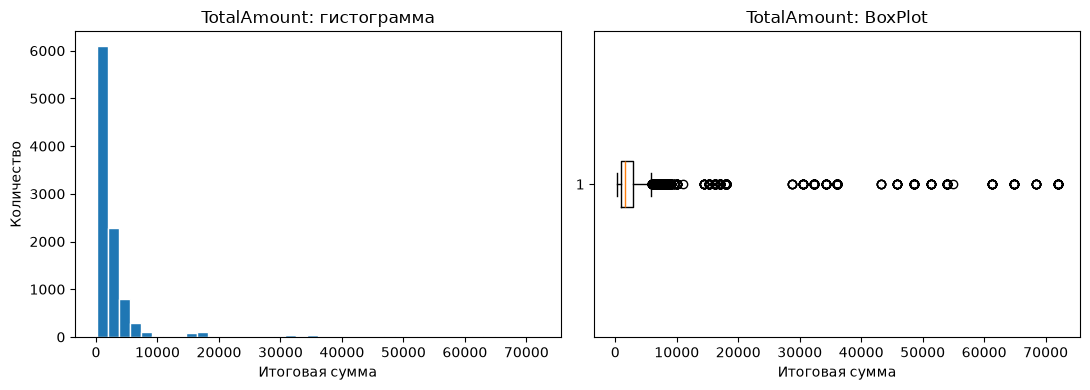

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(amount_values, bins=40, edgecolor="white")
axes[0].set(title="TotalAmount: гистограмма", xlabel="Итоговая сумма", ylabel="Количество")
axes[1].boxplot(amount_values, vert=False)
axes[1].set(title="TotalAmount: BoxPlot", xlabel="Итоговая сумма")
plt.tight_layout()
plt.show()

### Q–Q диаграмма логарифма TotalAmount

Для правосторонне скошенной положительной суммы Q–Q график строится для `log(TotalAmount)` и сравнивает его квантили с нормальными. Это графический способ оценить логнормальную форму исходного признака; статистический тест здесь не проводится.

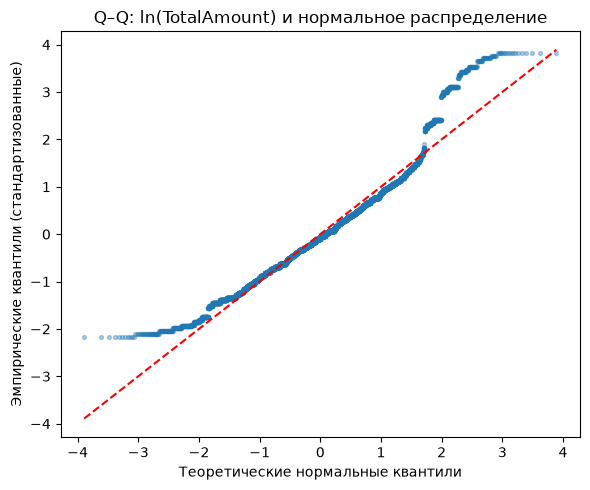

In [16]:
log_amount = np.log(amount_values[amount_values > 0])
fig, ax = plt.subplots(figsize=(6, 5))
normal_qq(ax, log_amount, "Q–Q: ln(TotalAmount) и нормальное распределение")
plt.tight_layout()
plt.show()